# Лабораторная работа 6. Работа с текстовыми данными (классификация текстов)

Датасет `SocialMedia.csv`: посты, репосты и комментарии пользователей ВКонтакте с разметкой по типам сообщений.

- ID — номер записи
- Text — текст сообщения
- TDate — дата
- TType — тип записи (пост / репост / комментарий к посту)
- TSource — источник
- TDouble, TRepost, TLike, TView, TComment — дубли, репосты, лайки, просмотры, комментарии
- TRegion, TRayon, TCity — регион, район, город автора
- TAge, TFriend, TReader — возраст автора, число друзей и подписчиков
- TClass — тип сообщения (класс)

In [1]:
import pandas as pd
import numpy as np
import re

from sklearn.feature_extraction.text import CountVectorizer
from nltk.stem.snowball import SnowballStemmer
from nltk.corpus import stopwords
from pymystem3 import Mystem
import nltk

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, confusion_matrix)

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## Загружаем данные

In [2]:
df = pd.read_csv("SocialMedia.csv")

print(df.shape)
display(df.head())
print(df['TClass'].nunique())
df['TClass'].value_counts().head(15)

(3071, 17)


,ID,Text,TDate,TType,TSource,TDouble,TRepost,TLike,TView,TComment,TRegion,TRayon,TCity,TAge,TFriend,TReader,TClass
0,79,Дарим 3 подвесных кресла! \n\n1. Подписываемся...,2021-02-10,Репост,Пользователь,131,0,0,32,0,Пермский край,NaN,Пермь,35,183,115,Реклама подвесных кресел
1,82,⚡Внимание! Новый розыгрыш!⚡\n \n📍Победителей б...,2021-02-10,Репост,Пользователь,96,0,1,32,0,Пермский край,NaN,Пермь,22,81,200,Реклама мебельного паблика
2,206,❤,2021-02-11,Репост,Пользователь,191,0,0,16,0,Пермский край,NaN,Соликамск,25,145,163,Сердечки
3,218,Наслаждайся Классической MOBA на Мобильном. Иг...,2021-02-11,Пост,Пользователь,115,0,0,0,0,Пермский край,Верещагинский район,Верещагино,19,298,229,Игры
4,273,Дарим 3 подвесных кресла! \n\n1. Подписываемся...,2021-02-10,Репост,Пользователь,131,0,0,95,0,Пермский край,NaN,Пермь,28,435,431,Реклама подвесных кресел


85


TClass
Конкурсы и розыгрыши                               648
Сердечки                                           242
Игры                                               171
Стримы разновозрастные                             131
Реклама непонятно чего                             117
Воронка лидерского тренинга                        109
Репосты различных пабликов участие в розыгрышах    100
Уточнение цены в диалоге.                           96
Непонятные плюсы                                    94
Реклама подвесных кресел                            93
Отзывы на фото                                      89
Алкоголь                                            88
Реклама рыбацкого магазина                          82
Роллы                                               67
Открытки                                            65
Name: count, dtype: int64

Классов 85, большинство из них по 2–20 сообщений, поэтому решаю задачу как бинарную. Самый большой класс «Конкурсы и розыгрыши» (648 записей). Но тексты розыгрышей встречаются ещё в трёх классах: «Репосты различных пабликов участие в розыгрышах», «Участник розыгрыша кофе Ностальджи», «Активный пользователь репостер различных розыгрышей». Разметка сделана скорее по автору, чем по тексту, и один и тот же пост про конкурс лежит в разных классах. Поэтому объединяю эти четыре класса в один: 1 — розыгрыш, 0 — всё остальное.

In [3]:
giveaway = ['Конкурсы и розыгрыши',
            'Репосты различных пабликов участие в розыгрышах',
            'Участник розыгрыша кофе Ностальджи',
            'Активный пользователь репостер различных розыгрышей']

df['target'] = df['TClass'].isin(giveaway).astype(int)
df['target'].value_counts()

target
0    2320
1     751
Name: count, dtype: int64

## Подготовка данных к последующему анализу

In [4]:
# Количество дубликатов по тексту и классу
df.duplicated(['Text', 'target']).sum()

np.int64(2812)

Дубликатов почти 92%: в основном это репосты одного и того же конкурса (один пост репостнули 234 раза) и короткие комментарии вроде «❤», «Live», «Цена?», «+». Если их оставить, одинаковые тексты попадут и в train, и в test, и модель просто запомнит их. Удаляю дубликаты, как в семинаре.

In [5]:
df = df.drop_duplicates(subset = ['Text', 'target']).reset_index(drop = True)

# тексты, которые после удаления дублей остались с разными метками
conflict = df['Text'].duplicated(keep = False)
display(df.loc[conflict, ['Text', 'TClass', 'target']].sort_values('Text'))

df = df[~conflict].reset_index(drop = True)
print(df.shape)

,Text,TClass,target
15,Между нами тает лёд... громкий КОНКУРС к нам и...,Алкоголь,0
16,Между нами тает лёд... громкий КОНКУРС к нам и...,Конкурсы и розыгрыши,1
39,Разыгрываем сет😎ДЛЯ НЕГО 😎\nУсловия те же: \n*...,Роллы,0
40,Разыгрываем сет😎ДЛЯ НЕГО 😎\nУсловия те же: \n*...,Репосты различных пабликов участие в розыгрышах,1
170,🎉🎉🎉встречайте😎😎😎🔥новый РОЗЫГРЫШ🎉🎉🎉\n🔥ПРИЗЫ ЗА ...,Реклама магазина микс,0
171,🎉🎉🎉встречайте😎😎😎🔥новый РОЗЫГРЫШ🎉🎉🎉\n🔥ПРИЗЫ ЗА ...,Активный пользователь репостер различных розыг...,1
190,🔥 ВНИМАНИЕ! КОНКУРС НА 24 ЧАСА! 🔥\n\nПриз на в...,Конкурсы и розыгрыши,1
191,🔥 ВНИМАНИЕ! КОНКУРС НА 24 ЧАСА! 🔥\n\nПриз на в...,Реклама паблика взрывная карамель,0
13,🔥КОНКУРС🔥 Разыгрываем 2 билета в кино на любой...,Конкурсы и розыгрыши,1
14,🔥КОНКУРС🔥 Разыгрываем 2 билета в кино на любой...,Реклама непонятно чего,0


(247, 18)


6 текстов розыгрышей лежат и в классе розыгрышей, и в рекламе (алкоголь, роллы, магазины). Для одного текста не может быть двух правильных ответов, поэтому убираю их совсем.

### Предобработка текста

In [6]:
# стоп-слова: качаем, только если их ещё нет
try:
    stop_words = set(stopwords.words('russian'))
except LookupError:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('russian'))
additional_stops = ['это', 'весь', 'который', 'свой', 'также']
stop_words.update(additional_stops)

stemmer = SnowballStemmer("russian")
mystem = Mystem()

In [7]:
# Функция предобработки со стеммингом
def preprocess_stemming(text):
    text = str(text).lower() # приводим к нижнему регистру
    text = text.replace('ё', 'е')
    text = re.sub(r'[^а-яa-z\s]', ' ', text) # убираем знаки препинания, эмодзи, ссылки, числа
    tokens = text.split() # токенизация
    stemmed_tokens = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words
    ]
    return ' '.join(stemmed_tokens)

Лемматизацию через mystem, как в семинаре. Только на Windows mystem при вызове на каждый текст отдельно работает очень долго (до 13 секунд на пост) и иногда падает. Поэтому склеиваю все тексты через разделитель `xxsepxx`, лемматизирую одним вызовом и режу обратно.

In [8]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace('ё', 'е')
    text = re.sub(r'[^а-яa-z\s]', ' ', text)
    return ' '.join(text.split())

# Функция предобработки с лемматизацией (сразу для всего столбца)
def preprocess_lemmatization(texts):
    joined = ' xxsepxx '.join(clean_text(t) for t in texts)
    lemmas = ''.join(mystem.lemmatize(joined)).split('xxsepxx')
    return [
        ' '.join(token for token in doc.split() if token not in stop_words)
        for doc in lemmas
    ]

In [9]:
df['clean_stem'] = df['Text'].apply(preprocess_stemming)
df['clean_lemma'] = preprocess_lemmatization(df['Text'])

# тексты только из эмодзи и знаков после чистки становятся пустыми
empty = df['clean_stem'] == ''
print('Пустых после чистки:', empty.sum())
print(df.loc[empty, 'Text'].tolist())

df = df[~empty].reset_index(drop = True)
print(df.shape)
print(df['target'].value_counts())

Пустых после чистки: 13
['❤', '❤️', '👍👍👍', '🥰', '❤❤❤', '+', '.', '✔✔✔', '😅😅😅', '🚖🤖❤', '❌', '💣💣💣', '❤😻']
(234, 20)
target
0    117
1    117
Name: count, dtype: int64


#### Пример полученной обработки

In [10]:
df[['Text', 'clean_stem', 'clean_lemma', 'target']].head(10)

,Text,clean_stem,clean_lemma,target
0,Дарим 3 подвесных кресла! \n\n1. Подписываемся...,дар подвесн кресл подписыва club подвесн кресл...,дарить подвесной кресло подписываться club под...,0
1,⚡Внимание! Новый розыгрыш!⚡\n \n📍Победителей б...,вниман нов розыгрыш победител прав участ розыг...,внимание новый розыгрыш победитель правило уча...,0
2,Наслаждайся Классической MOBA на Мобильном. Иг...,наслажда классическ moba мобильн игра топ игро...,наслаждаться классический moba мобильный играт...,0
3,Live,live,live,0
4,⭐ Вы не ждали? А мы запустим!\n \nРозыгрыш в п...,ждал запуст розыгрыш преддвер феврал х сам уда...,ждать запускать розыгрыш преддверие февраль х ...,0
5,ДАРИМ 5 кг Нарядов твоего размера к 8 марта 🌸🌸...,дар кг наряд тво размер март окол вещ обновлен...,дарить кг наряд твой размер март около вещь об...,1
6,"Возможно, кто-то ждёт валентинку от тебя?.. в ...",возможн ждет валентинк игр цел знаком https vk...,возможно ждать валентинка игра целовать знаком...,0
7,‼ ДОРОГИЕ ДРУЗЬЯ ‼ \n💣Пришло время запустить п...,дорог друз пришл врем запуст перв конкурс кото...,дорогой друг приходить время запускать первый ...,0
8,😉 Открытки и поздравления! 😉 \n\n Новая отк...,открытк поздравлен нов открытк смотрет https v...,открытка поздравление новый открытка смотреть ...,0
9,Узнай свою дату регистрации в сервисе vk.com/t...,узна дат регистрац сервис vk com tool,узнавать дата регистрация сервис vk com tool,0


## Bag of Words и разбиение 80/20

In [11]:
y = df['target']

X_train_s, X_test_s, y_train, y_test = train_test_split(
    df['clean_stem'], y, test_size = 0.2, random_state = 42, stratify = y
)
X_train_l = df.loc[X_train_s.index, 'clean_lemma']
X_test_l = df.loc[X_test_s.index, 'clean_lemma']

# CountVectorizer (мешок слов)
vec_stem = CountVectorizer()
X_train_stem_vec = vec_stem.fit_transform(X_train_s)
X_test_stem_vec = vec_stem.transform(X_test_s)

vec_lemma = CountVectorizer()
X_train_lemma_vec = vec_lemma.fit_transform(X_train_l)
X_test_lemma_vec = vec_lemma.transform(X_test_l)

print('Стемминг:', X_train_stem_vec.shape, ' Лемматизация:', X_train_lemma_vec.shape)
print('Доля розыгрышей: train', round(y_train.mean(), 3), ' test', round(y_test.mean(), 3))

Стемминг: (187, 2007)  Лемматизация: (187, 1919)
Доля розыгрышей: train 0.503  test 0.489


Текстов немного (тест меньше 50 штук), поэтому `max_features` не ограничиваю: словарь и так около 2 тыс. слов.

## Обучение моделей и расчет метрик качества

Модели те же, что в 4 работе: логистическая регрессия, kNN и SVM. Для повышения качества:

- подбор гиперпараметров через GridSearchCV с 5-кратной кросс-валидацией (как в семинаре), метрика F1;
- для kNN пробую косинусное расстояние, для текстов оно обычно лучше евклидова;
- композиция моделей soft voting из лучших трёх.

In [12]:
param_grids = {
    'LogReg': (LogisticRegression(max_iter = 1000, random_state = 42),
               {'C': [0.01, 0.1, 1.0, 10.0]}),
    'kNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 9, 15], 'metric': ['cosine', 'euclidean']}),
    'SVM': (SVC(probability = True, random_state = 42),
            {'C': [0.1, 1.0, 10.0], 'kernel': ['linear', 'rbf']}),
}

def train_models(X_train, X_test):
    models, proba = {}, {}
    for name, (model, grid) in param_grids.items():
        gs = GridSearchCV(model, grid, cv = 5, scoring = 'f1')
        gs.fit(X_train, y_train)
        print(f'{name}: {gs.best_params_}, F1 на CV = {gs.best_score_:.3f}')
        models[name] = gs.best_estimator_
        proba[name] = gs.best_estimator_.predict_proba(X_test)[:, 1]

    voting = VotingClassifier(estimators = list(models.items()), voting = 'soft')
    voting.fit(X_train, y_train)
    models['Soft voting'] = voting
    proba['Soft voting'] = voting.predict_proba(X_test)[:, 1]
    return models, proba

def get_metrics(proba):
    rows = {}
    for name, p in proba.items():
        pred = (p > 0.5).astype(int)
        rows[name] = {'Accuracy': accuracy_score(y_test, pred),
                      'F1': f1_score(y_test, pred),
                      'Precision': precision_score(y_test, pred),
                      'Recall': recall_score(y_test, pred),
                      'ROC-AUC': roc_auc_score(y_test, p)}
    return pd.DataFrame(rows).T.round(3)

### Стемминг

In [13]:
models_stem, proba_stem = train_models(X_train_stem_vec, X_test_stem_vec)
metrics_stem = get_metrics(proba_stem)
metrics_stem

LogReg: {'C': 0.1}, F1 на CV = 0.905


kNN: {'metric': 'cosine', 'n_neighbors': 3}, F1 на CV = 0.864


SVM: {'C': 0.1, 'kernel': 'linear'}, F1 на CV = 0.912


,Accuracy,F1,Precision,Recall,ROC-AUC
LogReg,0.851,0.857,0.808,0.913,0.957
kNN,0.809,0.836,0.719,1.000,0.934
SVM,0.872,0.875,0.840,0.913,0.953
Soft voting,0.894,0.898,0.846,0.957,0.967


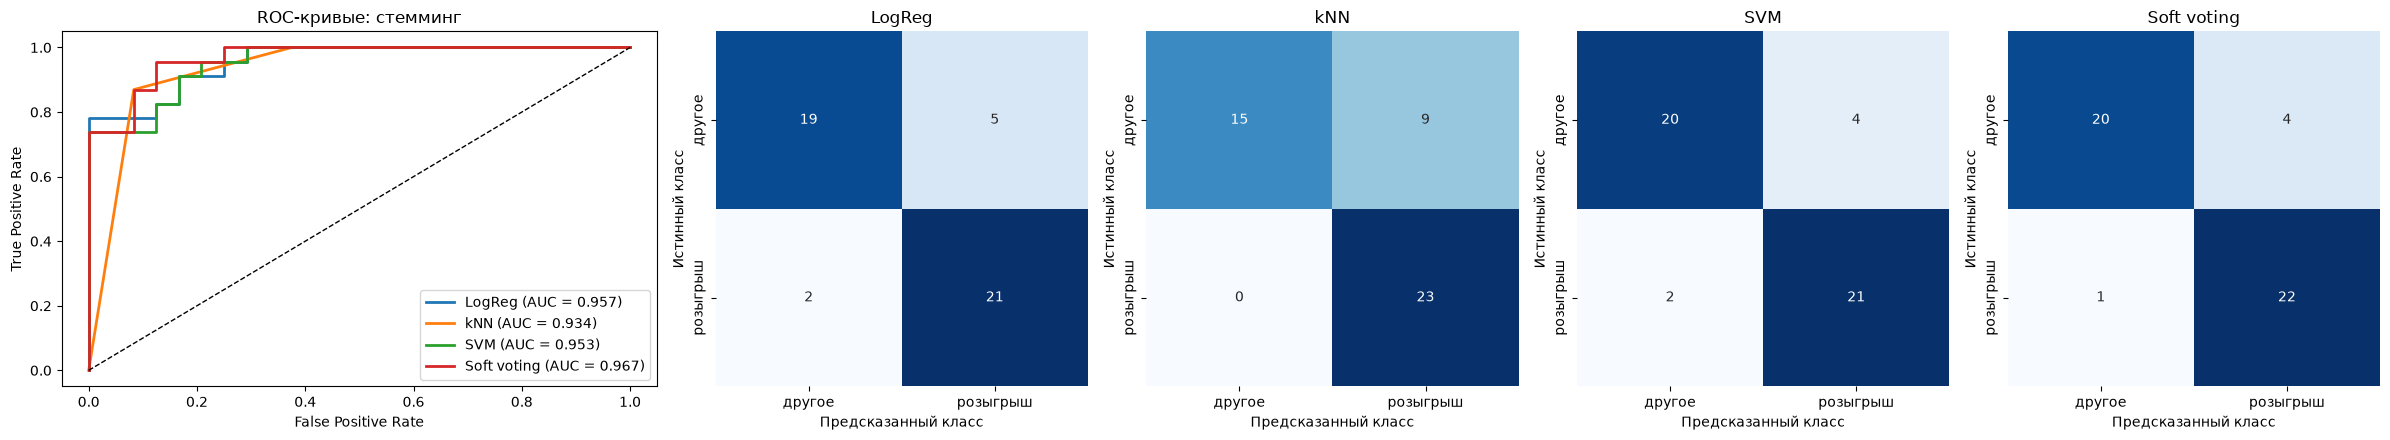

In [14]:
def plot_roc_cm(proba, title):
    fig, axes = plt.subplots(1, 5, figsize = (24, 4.5), gridspec_kw = {'width_ratios': [1.6, 1, 1, 1, 1]})

    for name, p in proba.items():
        fpr, tpr, _ = roc_curve(y_test, p)
        axes[0].plot(fpr, tpr, linewidth = 2, label = f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
    axes[0].plot([0, 1], [0, 1], 'k--', linewidth = 1)
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'ROC-кривые: {title}')
    axes[0].legend(loc = 'lower right')

    for ax, (name, p) in zip(axes[1:], proba.items()):
        cm = confusion_matrix(y_test, (p > 0.5).astype(int))
        sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', cbar = False, ax = ax,
                    xticklabels = ['другое', 'розыгрыш'], yticklabels = ['другое', 'розыгрыш'])
        ax.set_title(name)
        ax.set_xlabel('Предсказанный класс')
        ax.set_ylabel('Истинный класс')

    plt.tight_layout()
    plt.show()

plot_roc_cm(proba_stem, 'стемминг')

Лучше всех soft voting: Accuracy 0.894, F1 0.898, ROC-AUC 0.967. Из одиночных моделей лучший SVM с линейным ядром (F1 0.875), логистическая регрессия чуть хуже (0.857). kNN находит все розыгрыши (Recall 1.0), но платит за это precision 0.719: 9 обычных постов из 24 он тоже считает розыгрышами. По ROC-кривой kNN тоже самый слабый (AUC 0.934), у остальных 0.95–0.97.

Тест маленький, 47 текстов, поэтому одна ошибка меняет Accuracy на 0.021. Разница между LogReg и SVM это ровно один текст.

### Лемматизация

In [15]:
models_lemma, proba_lemma = train_models(X_train_lemma_vec, X_test_lemma_vec)
metrics_lemma = get_metrics(proba_lemma)
metrics_lemma

LogReg: {'C': 1.0}, F1 на CV = 0.922
kNN: {'metric': 'cosine', 'n_neighbors': 3}, F1 на CV = 0.845


SVM: {'C': 0.1, 'kernel': 'linear'}, F1 на CV = 0.918


,Accuracy,F1,Precision,Recall,ROC-AUC
LogReg,0.872,0.875,0.840,0.913,0.964
kNN,0.830,0.852,0.742,1.000,0.957
SVM,0.872,0.875,0.840,0.913,0.962
Soft voting,0.915,0.920,0.852,1.000,0.978


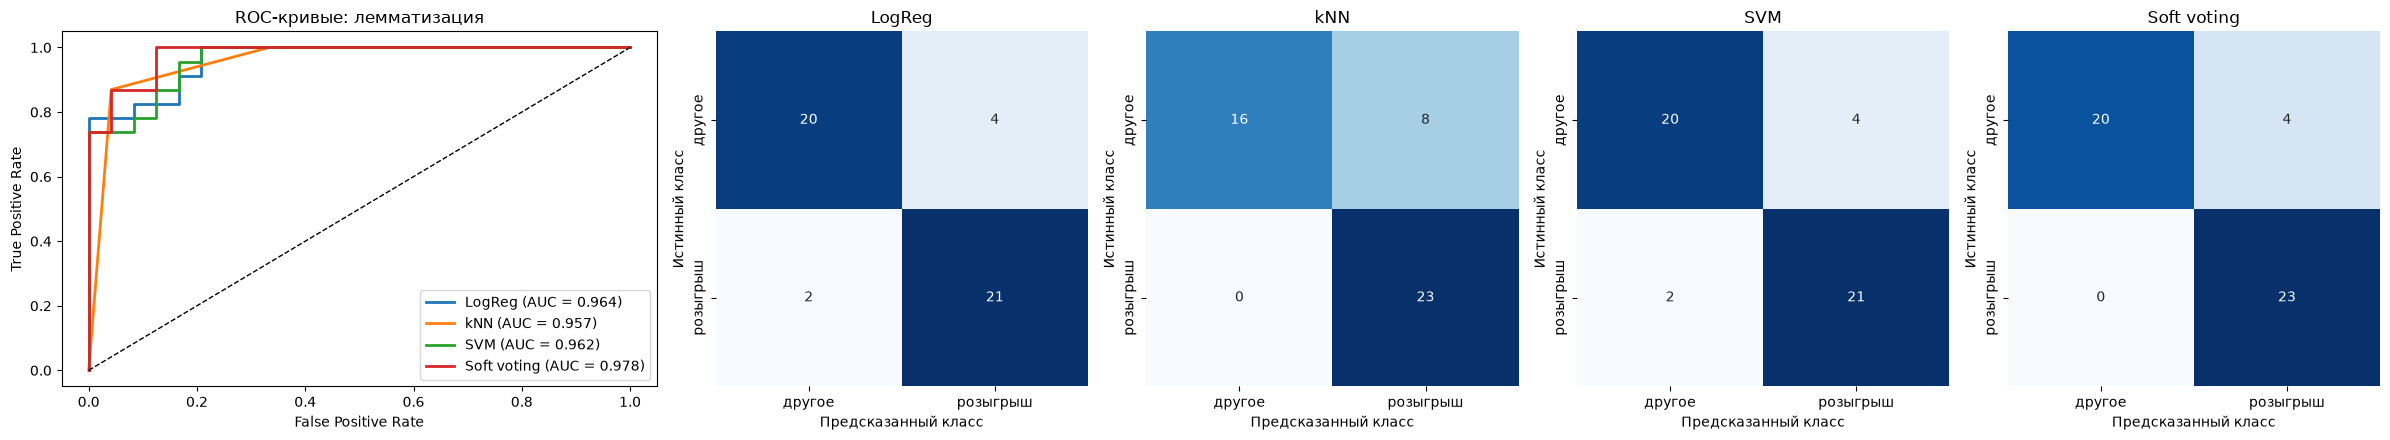

In [16]:
plot_roc_cm(proba_lemma, 'лемматизация')

### Сравнение стемминга и лемматизации

Accuracy                    F1             Precision           \
            Лемматизация Стемминг Лемматизация Стемминг Лемматизация Стемминг   
LogReg             0.872    0.851        0.875    0.857        0.840    0.808   
kNN                0.830    0.809        0.852    0.836        0.742    0.719   
SVM                0.872    0.872        0.875    0.875        0.840    0.840   
Soft voting        0.915    0.894        0.920    0.898        0.852    0.846   

                 ROC-AUC                Recall           
            Лемматизация Стемминг Лемматизация Стемминг  
LogReg             0.964    0.957        0.913    0.913  
kNN                0.957    0.934        1.000    1.000  
SVM                0.962    0.953        0.913    0.913  
Soft voting        0.978    0.967        1.000    0.957

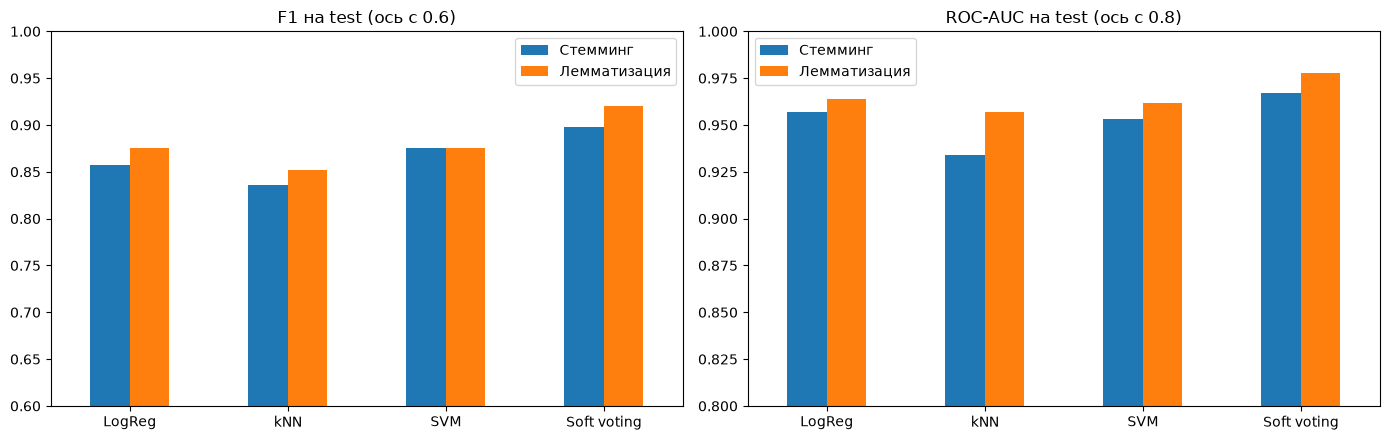

In [17]:
comparison = pd.concat([metrics_stem, metrics_lemma], axis = 1, keys = ['Стемминг', 'Лемматизация'])
comparison = comparison.swaplevel(axis = 1).sort_index(axis = 1, level = 0)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize = (14, 4.5))
pd.DataFrame({'Стемминг': metrics_stem['F1'], 'Лемматизация': metrics_lemma['F1']}).plot(kind = 'bar', ax = axes[0], rot = 0)
axes[0].set_ylim(0.6, 1)
axes[0].set_title('F1 на test (ось с 0.6)')
pd.DataFrame({'Стемминг': metrics_stem['ROC-AUC'], 'Лемматизация': metrics_lemma['ROC-AUC']}).plot(kind = 'bar', ax = axes[1], rot = 0)
axes[1].set_ylim(0.8, 1)
axes[1].set_title('ROC-AUC на test (ось с 0.8)')
plt.tight_layout()
plt.show()

## Посмотрим на модель изнутри

In [18]:
# Топ-15 слов-маркеров логистической регрессии
for vec, model, title in [(vec_stem, models_stem['LogReg'], 'Стемминг'),
                          (vec_lemma, models_lemma['LogReg'], 'Лемматизация')]:
    feature_names = vec.get_feature_names_out()
    coefficients = model.coef_[0]

    top_pos = coefficients.argsort()[::-1][:15]
    top_neg = coefficients.argsort()[:15]

    print(f'\n{title}')
    print('розыгрыш:', ', '.join(f'{feature_names[i]} ({coefficients[i]:.2f})' for i in top_pos))
    print('другое:  ', ', '.join(f'{feature_names[i]} ({coefficients[i]:.2f})' for i in top_neg))


Стемминг
розыгрыш: запис (0.46), club (0.45), феврал (0.44), конкурс (0.31), рубл (0.31), случайн (0.30), групп (0.28), подписа (0.27), подписчик (0.25), итог (0.24), бесплатн (0.23), сдела (0.23), наш (0.22), результат (0.22), счастливчик (0.22)
другое:   страниц (-0.36), лысьв (-0.26), друг (-0.17), мест (-0.17), ул (-0.17), конц (-0.16), ваш (-0.15), приятн (-0.15), втор (-0.14), перв (-0.14), друз (-0.14), ниж (-0.12), подарочн (-0.11), совушк (-0.10), kssovushka (-0.10)

Лемматизация
розыгрыш: запись (0.93), февраль (0.74), случайный (0.65), club (0.62), подписываться (0.58), рубль (0.58), результат (0.58), подарить (0.51), группа (0.49), итог (0.48), счастливчик (0.47), наш (0.45), конкурс (0.43), сделать (0.40), вступать (0.39)
другое:   страница (-0.76), лысьва (-0.57), друг (-0.45), конец (-0.41), первый (-0.40), разыгрывать (-0.40), второй (-0.38), день (-0.38), место (-0.34), совушка (-0.32), kssovushka (-0.32), ул (-0.31), время (-0.27), ваш (-0.27), дорогой (-0.27)


In [19]:
# Ошибки лучшей модели на лемматизации
p = proba_lemma['LogReg']
errors = pd.DataFrame({'Text': df.loc[X_test_l.index, 'Text'].str[:150],
                       'target': y_test, 'proba': p.round(2)})
errors[(p > 0.5).astype(int) != y_test]

,Text,target,proba
17,"❗5000р в подарок, подписчику сообщества на кар...",1,0.48
39,Вы влюблены? Мы – 100% да! Мы любим наших гост...,0,0.76
153,"😃Лысьва, а вот и новый конкурс! \n \n😎Хотите п...",0,0.88
133,🔥 Пoдapим 500 pублeй зa ЛAЙK ❤ \n \nПpaвилa уч...,1,0.46
30,Друзья! Совсем скоро День всех влюбленных ❤\nМ...,0,0.79
219,"❗❗❗ВНИМАНИЕ❗❗❗\n\n💝С 3 февраля по 8 марта ,я ...",0,0.81


In [20]:
# Проверка на своих текстах
my_texts = ['Разыгрываем сертификат на 3000 рублей! Подпишись и сделай репост, итоги 1 марта',
            'Продам диван в хорошем состоянии, цена договорная',
            'Всем удачи в конкурсе, я участвую']

my_vec = vec_lemma.transform(preprocess_lemmatization(my_texts))
pd.DataFrame({'Текст': my_texts,
              'Вероятность розыгрыша': models_lemma['LogReg'].predict_proba(my_vec)[:, 1].round(3)})

,Текст,Вероятность розыгрыша
0,Разыгрываем сертификат на 3000 рублей! Подпиши...,0.203
1,"Продам диван в хорошем состоянии, цена договорная",0.023
2,"Всем удачи в конкурсе, я участвую",0.050


- Маркеры розыгрышей в основном логичные: запись, конкурс, случайный, подписываться, итог, результат, счастливчик, club (ссылки на сообщества вида `[club123|...]`). Но в топе ещё и «февраль»: оно есть в 86% текстов розыгрышей и только в 16% остальных. Почти все конкурсы в данных приурочены к 14 и 23 февраля, и модель запомнила дату.
- Странно выглядит «разыгрывать» среди маркеров класса «другое» (−0.40). Это слово встречается в 8% текстов в обоих классах, потому что розыгрыши от рекламных пабликов (кресла, мебель, роллы, алкоголь) размечены по автору как реклама. Из-за этого мой текст «Разыгрываем сертификат на 3000 рублей! Подпишись и сделай репост» модель считает розыгрышем только с вероятностью 0.20.
- У стемминга одно слово иногда разваливается на два признака: «друг» и «друз» (от «друзья») стоят в топе отдельно. После лемматизации это один признак «друг» с весом −0.45.
- Из 6 ошибок логистической регрессии 4 ложные срабатывания, и все 4 по тексту это конкурсы: «Лысьва, а вот и новый конкурс!» (класс Алкоголь), розыгрыш маникюра (Индустрия красоты), два конкурса репостов от кафе (Доставка еды). Здесь модель права, а разметка нет.

## Вывод

- Решал задачу «розыгрыш / не розыгрыш». После удаления дубликатов (92% записей, в основном одинаковые репосты) и пустых текстов осталось 234 уникальных текста, классы сбалансированы 117 на 117.
- Лучший результат у soft voting на лемматизации: Accuracy 0.915, F1 0.920, Recall 1.0, ROC-AUC 0.978. Из одиночных моделей LogReg и SVM одинаковые (F1 0.875), kNN слабее всех и слишком часто ставит класс «розыгрыш».
- Лемматизация дала результат не хуже стемминга у всех моделей: F1 у LogReg 0.857 → 0.875, у kNN 0.836 → 0.852, у voting 0.898 → 0.920, ROC-AUC вырос на 0.007–0.023. Словарь меньше (1919 слов против 2007), потому что mystem сводит формы к одной лемме, а стеммер иногда режет одно слово по-разному. На тесте из 47 текстов каждая такая разница это один текст, поэтому смотрю ещё F1 на кросс-валидации: у LogReg 0.905 → 0.922 и у SVM 0.912 → 0.918 лемматизация тоже лучше, а у kNN наоборот (0.864 → 0.845).
- Главное ограничение в разметке: классы сделаны по автору или теме паблика, а не по тексту. Часть ошибок модели на самом деле ошибки разметки, а «февраль» в маркерах значит, что на постах из другого месяца модель будет работать хуже.